# Telecom Customer Churn Prediction

## Business Scenario

A telecom company is facing a serious customer churn problem.

Every time a customer leaves, the company loses revenue and must spend additional money to acquire a new customer.

The company wants to identify customers who are likely to leave so that proactive retention offers can be provided.

The objective of this project is to build a machine learning model that predicts whether a customer is likely to **Churn** or **Stay**.

## 1. Import Required Libraries

We import the libraries required for data analysis, visualization, preprocessing, model building, and evaluation.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

## 2. Load the Dataset

The dataset contains information about telecom customers and their churn status.

In [3]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Understand the Dataset

We examine the number of rows, columns, data types, and basic statistics.

In [5]:
print("Shape of dataset:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

Shape of dataset: (7043, 21)

Column Names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [6]:
print("\nDataset Information:")
df.info()


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  70

In [7]:
print("\nStatistical Summary:")
df.describe()


Statistical Summary:


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


## 4. Check Missing Values

Checking missing values is important before building the machine learning model.

In [8]:
print(df.isnull().sum())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [9]:
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'],
    errors='coerce'
)

print(df.isnull().sum())

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


In [10]:
df = df.dropna()

print("Dataset shape after removing missing values:", df.shape)

Dataset shape after removing missing values: (7032, 21)


## 5. Analyze Customer Churn

The target variable is `Churn`.

- Yes → Customer left the company
- No → Customer stayed with the company

In [11]:
print(df['Churn'].value_counts())

Churn
No     5163
Yes    1869
Name: count, dtype: int64


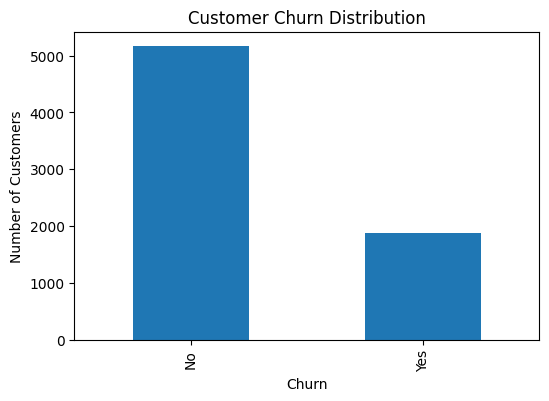

In [12]:
plt.figure(figsize=(6, 4))

df['Churn'].value_counts().plot(kind='bar')

plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.title("Customer Churn Distribution")

plt.show()

## 6. Select Input Features and Target

Customer information such as tenure, contract type, internet service, monthly charges, and payment method can influence churn.

We use the available customer attributes as input features and `Churn` as the target variable.

In [13]:
X = df.drop(['customerID', 'Churn'], axis=1)

y = df['Churn']

print("Input Features:")
print(X.columns.tolist())

print("\nTarget:")
print(y.head())

Input Features:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']

Target:
0     No
1     No
2    Yes
3     No
4    Yes
Name: Churn, dtype: object


## 7. Convert Categorical Variables

Machine learning models require numerical data.

We use one-hot encoding to convert categorical customer attributes into numerical values.

In [14]:
X = pd.get_dummies(X, drop_first=True)

print("Features after encoding:")
print(X.head())

Features after encoding:
   SeniorCitizen  tenure  MonthlyCharges  TotalCharges  gender_Male  \
0              0       1           29.85         29.85        False   
1              0      34           56.95       1889.50         True   
2              0       2           53.85        108.15         True   
3              0      45           42.30       1840.75         True   
4              0       2           70.70        151.65        False   

   Partner_Yes  Dependents_Yes  PhoneService_Yes  \
0         True           False             False   
1        False           False              True   
2        False           False              True   
3        False           False             False   
4        False           False              True   

   MultipleLines_No phone service  MultipleLines_Yes  ...  \
0                            True              False  ...   
1                           False              False  ...   
2                           False              False

In [15]:
y = y.map({
    'No': 0,
    'Yes': 1
})

print(y.value_counts())

Churn
0    5163
1    1869
Name: count, dtype: int64


## 8. Split the Dataset

The dataset is divided into:

- 80% training data
- 20% testing data

The model learns from the training data and is evaluated on unseen testing data.

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (5625, 30)
Testing data: (1407, 30)


## 9. Feature Scaling

The numerical features have different ranges.

StandardScaler is used to bring the features to a similar scale before training the Logistic Regression model.

In [17]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

## 10. Build the Logistic Regression Model

Logistic Regression is suitable because this is a binary classification problem.

The model predicts whether a customer is likely to:

- Stay
- Churn

In [18]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train_scaled, y_train)

print("Model training completed.")

Model training completed.


## 11. Predict Churn for Unseen Customers

The trained model is now used to predict churn for customers in the testing dataset.

In [19]:
y_pred = model.predict(X_test_scaled)

print("First 20 predictions:")
print(y_pred[:20])

First 20 predictions:
[0 1 0 0 0 0 0 0 1 0 1 0 1 0 0 1 1 1 0 0]


## 12. Churn Probability

The model can also calculate the probability that a customer will churn.

A higher probability means the customer is more likely to leave.

In [20]:
churn_probability = model.predict_proba(X_test_scaled)[:, 1]

print("First 10 churn probabilities:")
print(churn_probability[:10])

First 10 churn probabilities:
[0.01711495 0.59613179 0.00476432 0.20004408 0.10022205 0.4700293
 0.02661132 0.16414898 0.68614136 0.01518016]


## 13. Customer Classification

Based on the model prediction, customers are classified as:

- Likely to Stay
- Likely to Churn

In [21]:
results = pd.DataFrame({
    'Actual Churn': y_test.values,
    'Predicted Churn': y_pred,
    'Churn Probability': churn_probability
})

results['Prediction'] = results['Predicted Churn'].map({
    0: 'Likely to Stay',
    1: 'Likely to Churn'
})

results.head(10)

,Actual Churn,Predicted Churn,Churn Probability,Prediction
0,0,0,0.017115,Likely to Stay
1,0,1,0.596132,Likely to Churn
2,0,0,0.004764,Likely to Stay
3,1,0,0.200044,Likely to Stay
4,0,0,0.100222,Likely to Stay
5,1,0,0.470029,Likely to Stay
6,0,0,0.026611,Likely to Stay
7,0,0,0.164149,Likely to Stay
8,1,1,0.686141,Likely to Churn
9,0,0,0.015180,Likely to Stay


## 14. Model Evaluation

We use the following metrics:

- Accuracy
- Precision
- Recall
- F1 Score

In [22]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred)

recall = recall_score(y_test, y_pred)

f1 = f1_score(y_test, y_pred)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

Accuracy : 0.8038379530916845
Precision: 0.6475903614457831
Recall   : 0.5748663101604278
F1 Score : 0.6090651558073654


## 15. Classification Report

The classification report provides detailed performance information for both Stay and Churn classes.

In [23]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=['Stay', 'Churn']
    )
)

              precision    recall  f1-score   support

        Stay       0.85      0.89      0.87      1033
       Churn       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



## 16. Confusion Matrix

The confusion matrix shows how many customers were correctly and incorrectly classified.

In [24]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[916 117]
 [159 215]]


## 17. Understand the Confusion Matrix

In [25]:
tn, fp, fn, tp = cm.ravel()

print("True Negatives :", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives :", tp)

True Negatives : 916
False Positives: 117
False Negatives: 159
True Positives : 215


### Meaning of the Results

- **True Negative:** Customer stayed and was correctly predicted to stay.
- **False Positive:** Customer stayed but was incorrectly predicted to churn.
- **False Negative:** Customer churned but was incorrectly predicted to stay.
- **True Positive:** Customer churned and was correctly predicted to churn.

## 18. Business Analysis

### How many churn customers were correctly identified?

The number of correctly identified churn customers is the **True Positive (TP)** value from the confusion matrix.

### How many non-churn customers were misclassified?

The number of non-churn customers incorrectly classified as churn is the **False Positive (FP)** value.

### Which mistake is more costly?

A False Positive means a loyal customer is wrongly given a retention offer. This causes unnecessary marketing or discount costs.

A False Negative means an actual churn customer is missed. The company may lose that customer and future revenue.

For a telecom company, missing an actual churn customer can be more costly because the company loses future revenue and may need to spend more money to acquire a new customer.

Therefore, the company should pay special attention to **Recall for the Churn class**.

## 19. Confusion Matrix Visualization

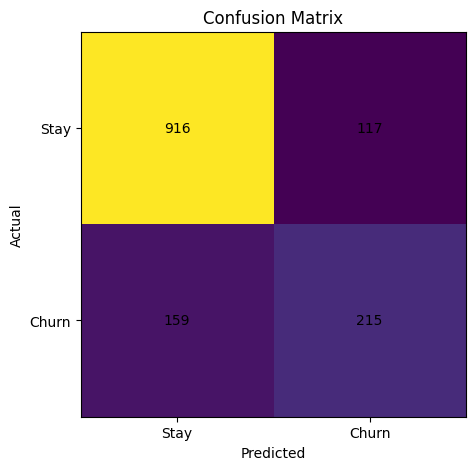

In [26]:
plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks([0, 1], ['Stay', 'Churn'])
plt.yticks([0, 1], ['Stay', 'Churn'])

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i, j],
            ha='center',
            va='center'
        )

plt.show()

## 20. Feature Importance

Logistic Regression coefficients help us understand which customer attributes have a stronger influence on the churn prediction.

In [27]:
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_[0]
})

feature_importance['Absolute Coefficient'] = abs(
    feature_importance['Coefficient']
)

feature_importance = feature_importance.sort_values(
    by='Absolute Coefficient',
    ascending=False
)

feature_importance.head(15)

,Feature,Coefficient,Absolute Coefficient
1,tenure,-1.347613,1.347613
2,MonthlyCharges,-0.851551,0.851551
10,InternetService_Fiber optic,0.727745,0.727745
3,TotalCharges,0.639028,0.639028
25,Contract_Two year,-0.602591,0.602591
24,Contract_One year,-0.310898,0.310898
21,StreamingTV_Yes,0.249702,0.249702
23,StreamingMovies_Yes,0.236368,0.236368
9,MultipleLines_Yes,0.214359,0.214359
28,PaymentMethod_Electronic check,0.181473,0.181473


## 21. Visualize Important Features

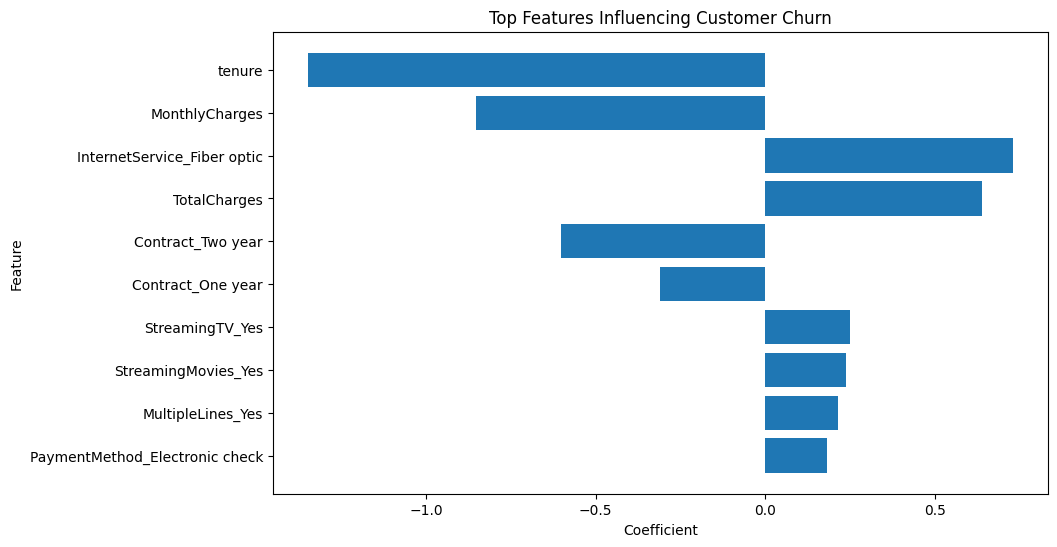

In [28]:
top_features = feature_importance.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features['Feature'],
    top_features['Coefficient']
)

plt.xlabel("Coefficient")
plt.ylabel("Feature")
plt.title("Top Features Influencing Customer Churn")

plt.gca().invert_yaxis()

plt.show()

## 22. Business Recommendation

The company should identify customers with a high predicted probability of churn and provide targeted retention offers.

Possible actions include:

- Special discounts
- Better service plans
- Loyalty benefits
- Personalized offers
- Customer support follow-up

This allows the company to focus its retention budget on customers who are most likely to leave.

## 23. Technical Improvement

The prediction can be made more reliable by comparing Logistic Regression with other classification models such as Random Forest, Gradient Boosting, or XGBoost.

Cross-validation and hyperparameter tuning can also be used to select the best model.

The classification threshold can also be adjusted to improve recall and reduce the number of customers who are likely to churn but are missed by the model.

## 24. Conclusion

A Logistic Regression model was developed to predict telecom customer churn.

The model uses customer attributes to estimate the probability of churn and classify customers as likely to stay or likely to churn.

The model was evaluated using Accuracy, Precision, Recall, F1 Score, and a Confusion Matrix.

From a business perspective, missing a customer who is actually going to churn can be more costly than wrongly flagging a loyal customer. Therefore, the company should focus on identifying as many actual churn customers as possible while controlling unnecessary retention offers.

The model can help the telecom company take proactive actions and reduce customer churn.